# Wan 2.1 T2V-1.3B: how do prefill latency and memory scale with sequence length?

**Research question:** How closely do prefill latency and memory scale with prompt length compared with theoretical FLOP/memory predictions?

**Definitions used here**
- *Prompt length* = **N**, the number of video latent tokens the DiT sees (frames x height x width after the VAE 4x/8x8 compression and 1x2x2 patchify). The text prompt is fixed at 512 tokens and only enters through cross-attention.
- *Prefill* = one DiT forward pass (one denoising step). A full generation is about 50 of these.

**Before running:** Runtime > Change runtime type > pick a GPU (T4 / L4 / A100). Then Runtime > Run all.

## 1. Setup

In [ ]:
!pip install -q -U diffusers transformers accelerate

In [ ]:
import torch, time, math, os, gc, contextlib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

assert torch.cuda.is_available(), "No GPU found. Runtime > Change runtime type > select a GPU."
dev = "cuda"
props = torch.cuda.get_device_properties(0)
GPU = props.name
TOTAL_GB = props.total_memory / 1e9
# bf16 needs compute capability >= 8.0 (not T4). Fall back to fp16 there.
DTYPE = torch.bfloat16 if props.major >= 8 else torch.float16
BYTES = 2

# Approximate dense tensor-core peak TFLOPs (fp16/bf16) and memory bandwidth GB/s.
SPECS = {"T4": (65, 320), "L4": (121, 300), "A100": (312, 1555), "H100": (989, 3350), "V100": (125, 900)}
PEAK_TFLOPS, BW_GBS = float("nan"), float("nan")
for k, (p, b) in SPECS.items():
    if k in GPU:
        PEAK_TFLOPS, BW_GBS = p, b
if "A100" in GPU and TOTAL_GB > 50:
    BW_GBS = 2039
# If your GPU is not recognised, set these by hand:
# PEAK_TFLOPS, BW_GBS = 100, 500

print(f"GPU: {GPU} | {TOTAL_GB:.1f} GB | dtype: {DTYPE} | peak {PEAK_TFLOPS} TFLOPs | BW {BW_GBS} GB/s")
print("torch", torch.__version__)

GPU: Tesla T4 | 15.6 GB | dtype: torch.float16 | peak 65 TFLOPs | BW 320 GB/s
torch 2.14.1+cu130


In [ ]:
# ---------------- Experiment config ----------------
MODEL_ID  = "Wan-AI/Wan2.1-T2V-1.3B-Diffusers"   # Diffusers-format repo
TEXT_LEN  = 512      # UMT5 context length used by Wan
WARMUP    = 2
REPEATS   = 5
LAT_H, LAT_W = 60, 104       # 480x832 video -> 60x104 latent
FRAMES    = [1, 2, 3, 4, 6, 8, 11, 14, 17, 21, 28, 36]   # latent frames (21 = 81 video frames)
SMALL_SHAPES = [(1, 16, 26), (1, 30, 52)]                 # to reach very small N
OUT_DIR   = "wan_prefill_results"
os.makedirs(OUT_DIR, exist_ok=True)

## 2. Load the DiT only (no VAE / T5 needed: we feed random latents and text embeddings)

In [ ]:
from diffusers import WanTransformer3DModel

try:
    model = WanTransformer3DModel.from_pretrained(MODEL_ID, subfolder="transformer", torch_dtype=DTYPE)
except Exception as e:
    raise RuntimeError(
        f"Could not load {MODEL_ID}. Check the repo name on Hugging Face "
        f"(Wan-AI/Wan2.1-T2V-1.3B-Diffusers) and your diffusers version.\n{e}")
model = model.to(dev).eval()

cfg = model.config
HEADS, HDIM = cfg.num_attention_heads, cfg.attention_head_dim
D = HEADS * HDIM
FFN, LAYERS = cfg.ffn_dim, cfg.num_layers
PT, PH, PW = cfg.patch_size
C_IN, TEXT_DIM = cfg.in_channels, cfg.text_dim
PARAMS = sum(p.numel() for p in model.parameters())
print(f"layers={LAYERS} d={D} heads={HEADS} head_dim={HDIM} ffn={FFN} patch={cfg.patch_size} "
      f"in_ch={C_IN} text_dim={TEXT_DIM} params={PARAMS/1e9:.2f}B")
print(f"Weights on GPU: {torch.cuda.memory_allocated()/1e9:.2f} GB")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/465 [00:00<?, ?B/s]

(…)ion_pytorch_model.safetensors.index.json:   0%|          | 0.00/73.3k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

layers=30 d=1536 heads=12 head_dim=128 ffn=8960 patch=[1, 2, 2] in_ch=16 text_dim=4096 params=1.42B
Weights on GPU: 2.85 GB


## 3. Analytical model

Per layer, per token (forward pass, 2 FLOPs per multiply-add):

| Component | FLOPs |
|---|---|
| Self-attn Q,K,V,O projections | 8 d^2 |
| Cross-attn Q,O projections | 4 d^2 |
| FFN (two matmuls) | 4 d F |
| Self-attn scores + weighted sum | 4 N d  *(quadratic in N)* |
| Cross-attn scores + weighted sum | 4 L d |
| Cross-attn K,V projection of text (once per layer) | 4 L d^2 |

**Memory (inference, no autograd):** weights + transient activations. With a fused attention kernel (flash / mem-efficient SDPA) there is no N x N matrix, so activations ~ N x (F + c d). With the naive `math` backend an N x N score matrix per head is materialised, adding ~ 2 x heads x N^2 x bytes.

In [ ]:
def tokens(shape):
    F, H, W = shape
    return (F // PT) * (H // PH) * (W // PW)

def flops_linear(N):   # terms linear in N
    return LAYERS * N * (12 * D**2 + 4 * D * FFN)

def flops_attn(N):     # quadratic term (self-attention)
    return LAYERS * 4 * N**2 * D

def flops_other(N):    # cross-attn scores + text K/V projections
    return LAYERS * (4 * N * TEXT_LEN * D + 4 * TEXT_LEN * D**2)

def flops_total(N):
    return flops_linear(N) + flops_attn(N) + flops_other(N)

def act_bytes_fused(N):
    return BYTES * N * (FFN + 6 * D)

def act_bytes_math(N):
    return act_bytes_fused(N) + 2 * HEADS * N**2 * BYTES

# crossover where quadratic attention FLOPs equal the linear FLOPs
Ns = np.arange(100, 100000)
cross = Ns[np.argmax(flops_attn(Ns) >= flops_linear(Ns) + flops_other(Ns))]
print(f"FLOPs/token (linear part): {flops_linear(1)/1e9:.2f} GFLOPs")
print(f"Attention equals linear FLOPs at N ~ {cross:,}")
N480 = tokens((21, LAT_H, LAT_W))
print(f"Full 81-frame 480p: N={N480:,}, total {flops_total(N480)/1e12:.1f} TFLOPs, "
      f"attention share {flops_attn(N480)/flops_total(N480):.0%}")
print(f"Naive-attention score matrix at that N: {act_bytes_math(N480)/1e9:.1f} GB (predicted OOM on most GPUs)")

FLOPs/token (linear part): 2.50 GFLOPs
Attention equals linear FLOPs at N ~ 14,136
Full 81-frame 480p: N=32,760, total 283.0 TFLOPs, attention share 70%
Naive-attention score matrix at that N: 52.7 GB (predicted OOM on most GPUs)


## 4. Benchmark harness

In [ ]:
from torch.nn.attention import sdpa_kernel, SDPBackend

def backend_ctx(name):
    if name == "math":
        return sdpa_kernel(SDPBackend.MATH)
    return contextlib.nullcontext()    # default: PyTorch picks flash / mem-efficient

def make_inputs(shape):
    F, H, W = shape
    x = torch.randn(1, C_IN, F, H, W, device=dev, dtype=DTYPE)
    t = torch.tensor([500.0], device=dev)
    e = torch.randn(1, TEXT_LEN, TEXT_DIM, device=dev, dtype=DTYPE)
    return x, t, e

def bench(shape, backend="default"):
    N = tokens(shape)
    gc.collect(); torch.cuda.empty_cache()
    weights = torch.cuda.memory_allocated()
    row = dict(F=shape[0], H=shape[1], W=shape[2], N=N, backend=backend, oom=False,
               lat_med=np.nan, lat_min=np.nan, lat_std=np.nan, peak_total_gb=np.nan, peak_act_gb=np.nan)
    x = t = e = None
    try:
        x, t, e = make_inputs(shape)
        with torch.inference_mode(), backend_ctx(backend):
            for _ in range(WARMUP):
                model(hidden_states=x, timestep=t, encoder_hidden_states=e, return_dict=False)
            torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
            times = []
            for _ in range(REPEATS):
                s, f = torch.cuda.Event(enable_timing=True), torch.cuda.Event(enable_timing=True)
                s.record()
                model(hidden_states=x, timestep=t, encoder_hidden_states=e, return_dict=False)
                f.record(); torch.cuda.synchronize()
                times.append(s.elapsed_time(f) / 1000)
        peak = torch.cuda.max_memory_allocated()
        row.update(lat_med=float(np.median(times)), lat_min=min(times), lat_std=float(np.std(times)),
                   peak_total_gb=peak/1e9, peak_act_gb=(peak - weights)/1e9)
    except torch.cuda.OutOfMemoryError:
        row["oom"] = True
    finally:
        del x, t, e
        gc.collect(); torch.cuda.empty_cache()
    return row

RESULTS = []
def save():
    pd.DataFrame(RESULTS).to_csv(f"{OUT_DIR}/results.csv", index=False)

def sweep(shapes, backend, stop_on_oom=True, tag="main"):
    for s in sorted(shapes, key=tokens):
        r = bench(s, backend); r["sweep"] = tag
        RESULTS.append(r); save()
        msg = "OOM" if r["oom"] else f"{r['lat_med']*1000:9.1f} ms | act {r['peak_act_gb']:6.2f} GB"
        print(f"[{backend:7s}] shape={s} N={r['N']:>6,}  {msg}")
        if r["oom"] and stop_on_oom:
            print("   -> stopping this sweep at first OOM"); break

# quick smoke test before the long sweeps
print(bench((1, 30, 52)))

{'F': 1, 'H': 30, 'W': 52, 'N': 390, 'backend': 'default', 'oom': False, 'lat_med': 0.0853682861328125, 'lat_min': 0.08407762908935547, 'lat_std': 0.0015435984268532396, 'peak_total_gb': 2.883245056, 'peak_act_gb': 0.03637504}


## 5. Sweeps

In [ ]:
# Sweep A: default attention (fused kernel). Main result.
shapes_main = SMALL_SHAPES + [(f, LAT_H, LAT_W) for f in FRAMES]
sweep(shapes_main, "default", tag="main")

[default] shape=(1, 16, 26) N=   104       81.0 ms | act   0.01 GB
[default] shape=(1, 30, 52) N=   390       97.3 ms | act   0.03 GB
[default] shape=(1, 60, 104) N= 1,560      340.5 ms | act   0.08 GB
[default] shape=(2, 60, 104) N= 3,120      783.9 ms | act   0.16 GB
[default] shape=(3, 60, 104) N= 4,680     1214.4 ms | act   0.24 GB
[default] shape=(4, 60, 104) N= 6,240     1821.5 ms | act   0.31 GB
[default] shape=(6, 60, 104) N= 9,360     3101.1 ms | act   0.47 GB
[default] shape=(8, 60, 104) N=12,480     4860.3 ms | act   0.62 GB
[default] shape=(11, 60, 104) N=17,160     8132.5 ms | act   0.85 GB
[default] shape=(14, 60, 104) N=21,840    12439.6 ms | act   1.08 GB
[default] shape=(17, 60, 104) N=26,520    17833.2 ms | act   1.32 GB
[default] shape=(21, 60, 104) N=32,760    28599.9 ms | act   1.62 GB
[default] shape=(28, 60, 104) N=43,680    57069.9 ms | act   2.16 GB
[default] shape=(36, 60, 104) N=56,160   100168.4 ms | act   2.78 GB


In [ ]:
# Sweep B: naive "math" attention. Expected: memory ~ N^2, OOM much earlier.
sweep(shapes_main, "math", tag="main")

[math   ] shape=(1, 16, 26) N=   104       70.1 ms | act   0.02 GB
[math   ] shape=(1, 30, 52) N=   390      138.3 ms | act   0.05 GB
[math   ] shape=(1, 60, 104) N= 1,560      618.6 ms | act   0.33 GB
[math   ] shape=(2, 60, 104) N= 3,120     1825.8 ms | act   1.19 GB
[math   ] shape=(3, 60, 104) N= 4,680     3372.7 ms | act   2.57 GB
[math   ] shape=(4, 60, 104) N= 6,240     5614.2 ms | act   4.47 GB
[math   ] shape=(6, 60, 104) N= 9,360    12825.2 ms | act   9.86 GB
[math   ] shape=(8, 60, 104) N=12,480  OOM
   -> stopping this sweep at first OOM


In [ ]:
# Sweep C: same N, different shapes (frames vs. resolution). Does only N matter?
same_N = [(4, 60, 104), (8, 30, 104), (16, 30, 52)]    # all N = 6,240
print([tokens(s) for s in same_N])
sweep(same_N, "default", stop_on_oom=False, tag="sameN")

[6240, 6240, 6240]
[default] shape=(4, 60, 104) N= 6,240     1823.3 ms | act   0.31 GB
[default] shape=(8, 30, 104) N= 6,240     1822.3 ms | act   0.31 GB
[default] shape=(16, 30, 52) N= 6,240     1826.1 ms | act   0.31 GB


## 6. Analysis: measured vs. predicted

In [ ]:
df = pd.DataFrame(RESULTS)
d_def  = df[(df.backend == "default") & (df.sweep == "main") & (~df.oom)].sort_values("N").reset_index(drop=True)
d_math = df[(df.backend == "math") & (df.sweep == "main") & (~df.oom)].sort_values("N").reset_index(drop=True)

d_def["flops"] = flops_total(d_def.N.values)
d_def["tflops_achieved"] = d_def.flops / d_def.lat_med / 1e12
d_def["mfu"] = d_def.tflops_achieved / PEAK_TFLOPS
d_def["pred_act_fused_gb"] = act_bytes_fused(d_def.N.values) / 1e9

# Calibrate ONE constant (effective TFLOPs) at the largest N, then see whether the SHAPE of the
# FLOP model matches at all other N.
calib = d_def.lat_med.iloc[-1] / d_def.flops.iloc[-1]
d_def["pred_lat_flops"] = d_def.flops * calib
d_def["lat_ratio_meas_over_pred"] = d_def.lat_med / d_def.pred_lat_flops
# Roofline lower bound: max(compute at peak, weight read at peak bandwidth)
d_def["roofline_lb"] = np.maximum(d_def.flops / (PEAK_TFLOPS * 1e12), PARAMS * BYTES / (BW_GBS * 1e9))

def loglog_slope(x, y):
    return np.polyfit(np.log(x), np.log(y), 1)[0]

big = d_def[d_def.N >= 4000]
if len(big) >= 3:
    s_lat  = loglog_slope(big.N, big.lat_med)
    s_th   = loglog_slope(big.N, big.flops)
    s_mem  = loglog_slope(big.N, big.peak_act_gb)
    s_memp = loglog_slope(big.N, big.pred_act_fused_gb)
    print(f"Log-log slope, N>=4000 (1 = linear, 2 = quadratic):")
    print(f"  latency  measured {s_lat:.2f}  vs FLOP model {s_th:.2f}")
    print(f"  act. mem measured {s_mem:.2f}  vs fused-attention model {s_memp:.2f}")

# Fit latency = a*N + b*N^2 + c and compare b/a with the FLOP model
A = np.vstack([d_def.N, d_def.N**2, np.ones(len(d_def))]).T
a, b, c = np.linalg.lstsq(A, d_def.lat_med.values, rcond=None)[0]
th_ratio = (LAYERS * 4 * D) / (LAYERS * (12 * D**2 + 4 * D * FFN + 4 * TEXT_LEN * D))
print(f"\nLatency fit: {a:.3e} N + {b:.3e} N^2 + {c:.3e}")
print(f"  fitted b/a = {b/a:.3e} | FLOP-model b/a = {th_ratio:.3e} | ratio = {(b/a)/th_ratio:.2f}")
print(f"  fixed overhead c = {c*1000:.1f} ms")

cols = ["N", "lat_med", "pred_lat_flops", "lat_ratio_meas_over_pred", "tflops_achieved", "mfu",
        "peak_act_gb", "pred_act_fused_gb"]
display(d_def[cols].round(4))

Log-log slope, N>=4000 (1 = linear, 2 = quadratic):
  latency  measured 1.73  vs FLOP model 1.51
  act. mem measured 0.99  vs fused-attention model 1.00

Latency fit: -2.632e-04 N + 3.565e-08 N^2 + 1.157e+00
  fitted b/a = -1.355e-04 | FLOP-model b/a = 7.102e-05 | ratio = -1.91
  fixed overhead c = 1156.7 ms


,N,lat_med,pred_lat_flops,lat_ratio_meas_over_pred,tflops_achieved,mfu,peak_act_gb,pred_act_fused_gb
0,104,0.0519,0.0574,0.9036,8.0346,0.1236,0.0133,0.0038
1,104,0.0810,0.0574,1.4107,5.1463,0.0792,0.0133,0.0038
2,390,0.0973,0.1632,0.5959,12.1826,0.1874,0.0279,0.0142
3,390,0.0857,0.1632,0.5250,13.8277,0.2127,0.0279,0.0142
4,1560,0.2986,0.6394,0.4670,15.5470,0.2392,0.0830,0.0567
5,1560,0.3405,0.6394,0.5325,13.6350,0.2098,0.0830,0.0567
6,3120,0.7839,1.3824,0.5671,12.8030,0.1970,0.1617,0.1134
7,3120,0.6600,1.3824,0.4774,15.2069,0.2340,0.1617,0.1134
8,4680,1.2144,2.2490,0.5400,13.4454,0.2069,0.2382,0.1701
9,4680,1.0708,2.2490,0.4761,15.2485,0.2346,0.2382,0.1701


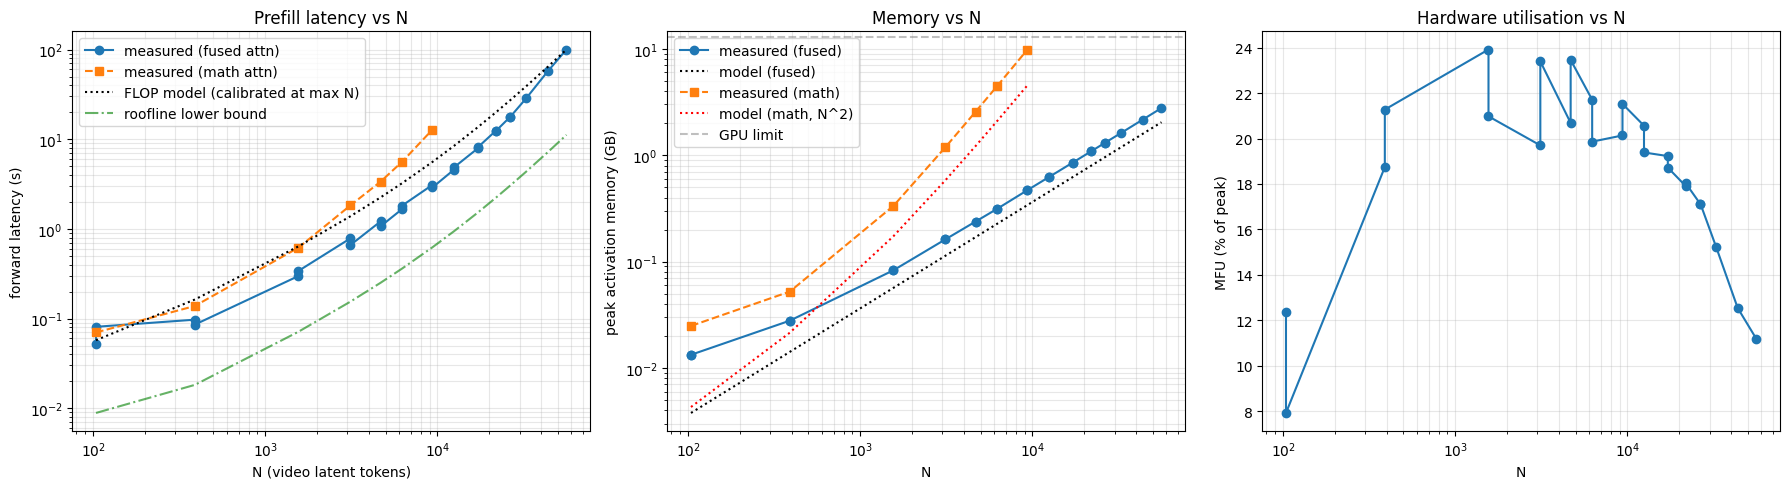

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))

# (1) latency
ax[0].loglog(d_def.N, d_def.lat_med, "o-", label="measured (fused attn)")
if len(d_math): ax[0].loglog(d_math.N, d_math.lat_med, "s--", label="measured (math attn)")
ax[0].loglog(d_def.N, d_def.pred_lat_flops, "k:", label="FLOP model (calibrated at max N)")
ax[0].loglog(d_def.N, d_def.roofline_lb, "g-.", label="roofline lower bound", alpha=.6)
ax[0].set(xlabel="N (video latent tokens)", ylabel="forward latency (s)", title="Prefill latency vs N")
ax[0].legend(); ax[0].grid(True, which="both", alpha=.3)

# (2) memory
ax[1].loglog(d_def.N, d_def.peak_act_gb, "o-", label="measured (fused)")
ax[1].loglog(d_def.N, act_bytes_fused(d_def.N.values)/1e9, "k:", label="model (fused)")
if len(d_math):
    ax[1].loglog(d_math.N, d_math.peak_act_gb, "s--", label="measured (math)")
    ax[1].loglog(d_math.N, act_bytes_math(d_math.N.values)/1e9, "r:", label="model (math, N^2)")
ax[1].axhline(TOTAL_GB - PARAMS*BYTES/1e9, color="gray", ls="--", alpha=.5, label="GPU limit")
ax[1].set(xlabel="N", ylabel="peak activation memory (GB)", title="Memory vs N")
ax[1].legend(); ax[1].grid(True, which="both", alpha=.3)

# (3) utilisation
ax[2].semilogx(d_def.N, d_def.mfu * 100, "o-")
ax[2].set(xlabel="N", ylabel="MFU (% of peak)", title="Hardware utilisation vs N")
ax[2].grid(True, which="both", alpha=.3)

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/wan_prefill_scaling.png", dpi=150)
plt.show()

In [ ]:
# Does only N matter? Compare shapes with identical N.
sn = df[(df.sweep == "sameN") & (~df.oom)][["F", "H", "W", "N", "lat_med", "peak_act_gb"]]
display(sn)
if len(sn) > 1:
    print(f"Latency spread at fixed N: {(sn.lat_med.max()/sn.lat_med.min()-1)*100:.1f}%")

# Where did each backend run out of memory?
oom = df[df.oom].groupby("backend").N.min()
print("\nSmallest N that hit OOM:", oom.to_dict() or "none (try larger FRAMES)")

,F,H,W,N,lat_med,peak_act_gb
33,4,60,104,6240,1.823261,0.313563
34,8,30,104,6240,1.822288,0.313563
35,16,30,52,6240,1.826118,0.313563


Latency spread at fixed N: 0.2%

Smallest N that hit OOM: {'math': 12480}


## 7. How to read the results

- **Latency:** if the slope on the log-log plot rises from ~1 toward ~2 as N grows, and the crossover sits near the N predicted in section 3, the FLOP model holds. Measured latency sitting *above* the prediction at small N is kernel-launch / memory-bound overhead (compare against the roofline line). A drop in MFU at large N means attention is running less efficiently than the matmuls.
- **Memory:** with fused attention, activation memory should be ~linear in N (slope ~1). The math backend should show slope ~2 and OOM early. A constant gap between measured and predicted memory is allocator overhead plus temporaries not in the simple formula (rescale the constant `6*D` if you want a tighter fit).
- **Same-N check:** near-identical latency for different (frames, height, width) shapes with the same N confirms N is the right scaling variable.
- **Caveats:** results are for one GPU type and one dtype (T4 uses fp16, others bf16); Colab GPUs share thermal and clock conditions, so use the spread across repeats.

Results are saved to `wan_prefill_results/results.csv` and `wan_prefill_scaling.png`.

In [ ]:
try:
    from google.colab import files
    files.download(f"{OUT_DIR}/results.csv")
    files.download(f"{OUT_DIR}/wan_prefill_scaling.png")
except Exception as e:
    print("Download manually from the file browser:", e)